# Jakość wina: analiza danych i pytania badawcze

EDA dwóch zbiorów: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine%2Bquality)
(Cortez i in., 2009; CC BY 4.0) oraz [Wine Reviews](https://www.kaggle.com/datasets/zynicide/wine-reviews)
(Zack Thoutt / Wine Enthusiast; CC BY-NC-SA 4.0).

Dane są już w `data/raw`. Uruchom komórki od góry do dołu.
Zbiory opisują różne wina i mają różne skale ocen, dlatego analizujemy je osobno.

In [1]:
from pathlib import Path
from collections import Counter
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT / "wine_quality_etap1"
DATA = ROOT / "data" / "raw"
FIGURES = ROOT / "output" / "figures"
TABLES = ROOT / "output" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

COLORS = ["#853d50", "#417c80"]
TYPES = {"red": "Czerwone", "white": "Białe"}
LABELS = {
    "fixed acidity": "Kwasowość stała", "volatile acidity": "Kwasowość lotna",
    "citric acid": "Kwas cytrynowy", "residual sugar": "Cukier resztkowy",
    "chlorides": "Chlorki", "free sulfur dioxide": "Wolny SO₂",
    "total sulfur dioxide": "Całkowity SO₂", "density": "Gęstość",
    "pH": "pH", "sulphates": "Siarczany", "alcohol": "Alkohol",
}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


def show_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", encoding="utf-8-sig")
    display(frame.round(3))


def show_plot(name):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Dane liczbowe: czyszczenie i statystyki

Usuwamy identyczne wiersze osobno dla każdego typu wina. Powtórzenia mogą być rzeczywistymi
pomiarami, dlatego korelacje sprawdzimy też w danych surowych. Wartości odstających nie usuwamy.

In [2]:
raw_wines = {
    kind: pd.read_csv(DATA / f"winequality-{kind}.csv", sep=";")
    for kind in TYPES
}
wines = {kind: frame.drop_duplicates() for kind, frame in raw_wines.items()}

show_table(pd.DataFrame({
    TYPES[kind]: {
        "Wiersze surowe": len(raw_wines[kind]),
        "Po usunięciu powtórzeń": len(frame),
        "Brakujące wartości": frame.isna().sum().sum(),
        "Średnia quality": frame.quality.mean(),
        "Mediana quality": frame.quality.median(),
        "Oceny 5 lub 6 (%)": 100 * frame.quality.isin([5, 6]).mean(),
        "Oceny ≥ 7 (%)": 100 * frame.quality.ge(7).mean(),
    }
    for kind, frame in wines.items()
}), "numeric_overview")

for kind, frame in wines.items():
    print(TYPES[kind])
    show_table(frame.describe().T, f"numeric_describe_{kind}")

iqr_outliers = {}
for kind, frame in wines.items():
    features = frame.drop(columns="quality")
    q1, q3 = features.quantile(0.25), features.quantile(0.75)
    iqr = q3 - q1
    iqr_outliers[kind] = ((features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)).sum()
show_table(pd.DataFrame(iqr_outliers), "iqr_outliers")

Czerwone
Białe


,Czerwone,Białe
Wiersze surowe,1599.000,4898.000
Po usunięciu powtórzeń,1359.000,3961.000
Brakujące wartości,0.000,0.000
Średnia quality,5.623,5.855
Mediana quality,6.000,6.000
Oceny 5 lub 6 (%),81.825,74.804
Oceny ≥ 7 (%),13.539,20.828


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.311,1.737,4.600,7.100,7.900,9.200,15.900
volatile acidity,1359.0,0.529,0.183,0.120,0.390,0.520,0.640,1.580
citric acid,1359.0,0.272,0.196,0.000,0.090,0.260,0.430,1.000
residual sugar,1359.0,2.523,1.352,0.900,1.900,2.200,2.600,15.500
chlorides,1359.0,0.088,0.049,0.012,0.070,0.079,0.091,0.611
free sulfur dioxide,1359.0,15.893,10.447,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1359.0,46.826,33.409,6.000,22.000,38.000,63.000,289.000
density,1359.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1359.0,3.310,0.155,2.740,3.210,3.310,3.400,4.010
sulphates,1359.0,0.659,0.171,0.330,0.550,0.620,0.730,2.000


,count,mean,std,min,25%,50%,75%,max
fixed acidity,3961.0,6.839,0.867,3.800,6.300,6.800,7.300,14.200
volatile acidity,3961.0,0.281,0.103,0.080,0.210,0.260,0.330,1.100
citric acid,3961.0,0.334,0.122,0.000,0.270,0.320,0.390,1.660
residual sugar,3961.0,5.915,4.862,0.600,1.600,4.700,8.900,65.800
chlorides,3961.0,0.046,0.023,0.009,0.035,0.042,0.050,0.346
free sulfur dioxide,3961.0,34.889,17.210,2.000,23.000,33.000,45.000,289.000
total sulfur dioxide,3961.0,137.194,43.129,9.000,106.000,133.000,166.000,440.000
density,3961.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,3961.0,3.195,0.152,2.720,3.090,3.180,3.290,3.820
sulphates,3961.0,0.490,0.114,0.220,0.410,0.480,0.550,1.080


,red,white
fixed acidity,41,106
volatile acidity,19,133
citric acid,1,223
residual sugar,126,16
chlorides,87,178
free sulfur dioxide,26,44
total sulfur dioxide,45,14
density,35,6
pH,28,46
sulphates,55,96


,red,white
quality,,
3,10,20
4,53,153
5,577,1175
6,535,1788
7,167,689
8,17,131
9,0,5


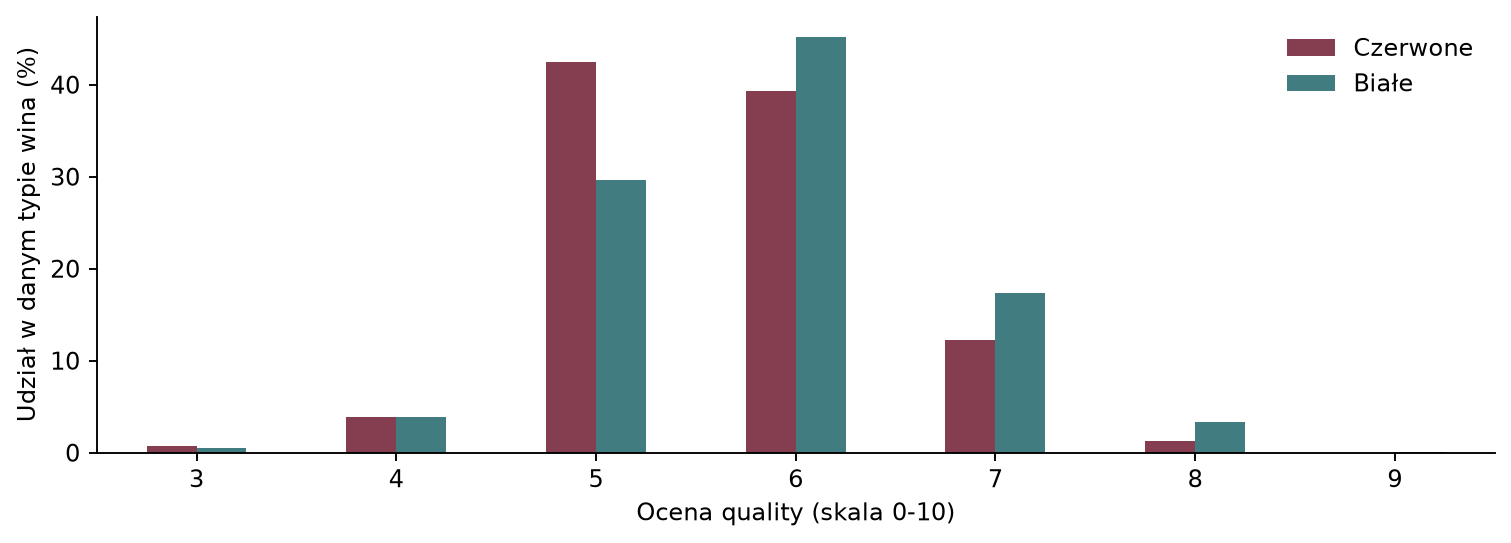

In [3]:
quality_counts = pd.DataFrame({
    kind: frame.quality.value_counts().sort_index()
    for kind, frame in wines.items()
}).fillna(0).astype(int)
show_table(quality_counts, "quality_counts")

percentages = quality_counts / quality_counts.sum() * 100
ax = percentages.rename(columns=TYPES).plot.bar(figsize=(9, 3.3), color=COLORS, rot=0)
ax.set(xlabel="Ocena quality (skala 0-10)", ylabel="Udział w danym typie wina (%)")
ax.legend(frameon=False)
show_plot("01_quality_distribution")

Oceny 5 i 6 dominują, a skrajne oceny są rzadkie. Do opisu zależności używamy korelacji
rang Spearmana, ponieważ `quality` jest oceną porządkową. Korelacja nie oznacza przyczynowości.

Spearman: alkohol i jakość, przed i po usunięciu powtórzeń


,red,white
Kwasowość stała,0.112,-0.094
Kwasowość lotna,-0.387,-0.185
Kwas cytrynowy,0.219,0.030
Cukier resztkowy,0.026,-0.092
Chlorki,-0.204,-0.333
Wolny SO₂,-0.059,0.033
Całkowity SO₂,-0.197,-0.203
Gęstość,-0.184,-0.383
pH,-0.043,0.136
Siarczany,0.381,0.036


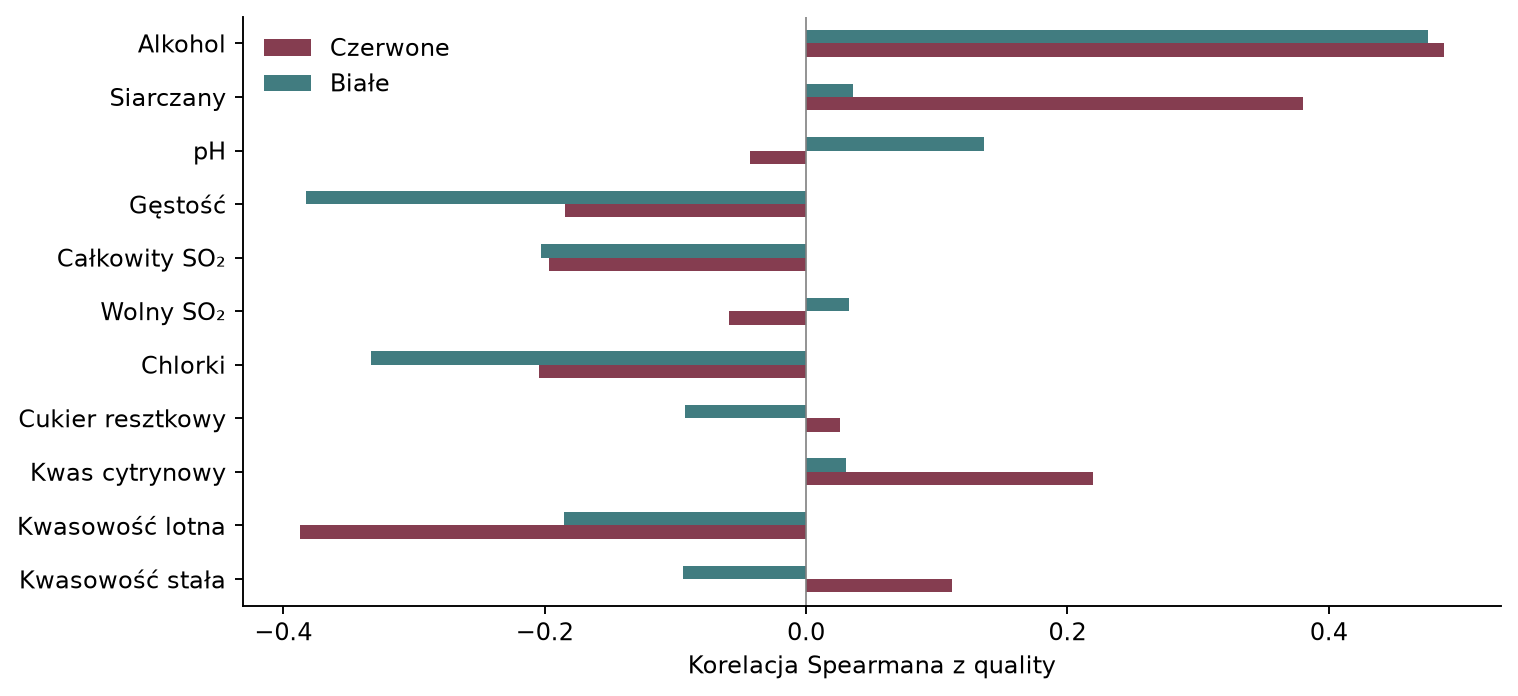

,Czerwone,Białe
Surowe,0.479,0.440
Oczyszczone,0.488,0.476


In [4]:
correlations = pd.DataFrame({
    kind: frame.corr(method="spearman")["quality"].drop("quality")
    for kind, frame in wines.items()
})
show_table(correlations.rename(index=LABELS), "spearman_quality")

ax = correlations.rename(index=LABELS, columns=TYPES).plot.barh(
    figsize=(9, 4.2), color=COLORS
)
ax.axvline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Korelacja Spearmana z quality", ylabel="")
ax.legend(frameon=False)
show_plot("02_correlations")

print("Spearman: alkohol i jakość, przed i po usunięciu powtórzeń")
display(pd.DataFrame({
    TYPES[kind]: {
        "Surowe": raw_wines[kind].alcohol.corr(raw_wines[kind].quality, method="spearman"),
        "Oczyszczone": frame.alcohol.corr(frame.quality, method="spearman"),
    }
    for kind, frame in wines.items()
}).round(3))

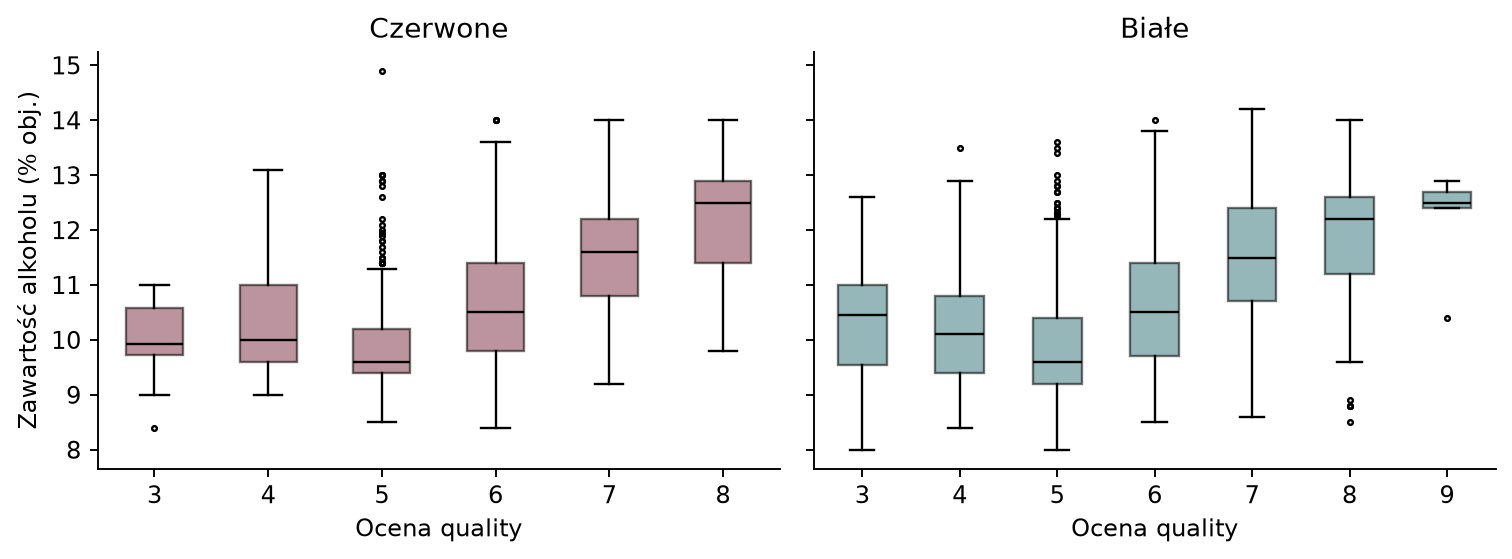

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (kind, title), color in zip(axes, TYPES.items(), COLORS):
    frame = wines[kind]
    scores = sorted(frame.quality.unique())
    ax.boxplot(
        [frame.loc[frame.quality == score, "alcohol"] for score in scores],
        tick_labels=scores, patch_artist=True,
        boxprops={"facecolor": color, "alpha": 0.55},
        medianprops={"color": "black"}, flierprops={"markersize": 2},
    )
    ax.set(title=title, xlabel="Ocena quality")
axes[0].set_ylabel("Zawartość alkoholu (% obj.)")
show_plot("03_alcohol_quality")

Alkohol jest dodatnio skorelowany z oceną w obu typach (ρ około 0,48).
W czerwonych winach widoczne są też ujemny związek kwasowości lotnej i dodatni siarczanów.
Pojedyncze korelacje nie opisują niezależnego wpływu cech.

## 2. Recenzje: czyszczenie i rozkłady

Pomijamy indeks CSV, usuwamy identyczne rekordy, a następnie powtórzone opisy po normalizacji
liter i białych znaków. Zachowujemy pierwsze wystąpienie. Nie uzupełniamy brakujących cen.

In [6]:
raw_reviews = pd.read_csv(DATA / "winemag-data-130k-v2.csv", index_col=0)
missing = raw_reviews.isna().sum()
show_table(pd.DataFrame({
    "braki_n": missing,
    "braki_proc": 100 * missing / len(raw_reviews),
}).sort_values("braki_n", ascending=False), "reviews_missing")

distinct_reviews = raw_reviews.drop_duplicates().copy()
distinct_reviews["description_key"] = (
    distinct_reviews.description.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)
reviews = distinct_reviews.drop_duplicates("description_key").copy()
reviews["word_count"] = reviews.description.str.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?").str.len()
reviews["char_count"] = reviews.description.str.len()
priced = reviews.loc[reviews.price > 0]

print(f"Recenzje: {len(raw_reviews)} → {len(distinct_reviews)} → {len(reviews)}")
print(f"Recenzje z ceną: {len(priced)}")
show_table(reviews[["points", "price", "word_count", "char_count"]].describe(), "reviews_describe")
show_table(reviews.country.value_counts().head(10).to_frame("n"), "country_counts")
show_table(reviews.variety.value_counts().head(10).to_frame("n"), "variety_counts")

Recenzje: 129971 → 119988 → 119954
Recenzje z ceną: 111566


,braki_n,braki_proc
region_2,79460,61.137
designation,37465,28.826
taster_twitter_handle,31213,24.015
taster_name,26244,20.192
region_1,21247,16.347
price,8996,6.922
province,63,0.048
country,63,0.048
variety,1,0.001
points,0,0.000


,points,price,word_count,char_count
count,119954.000,111566.000,119954.000,119954.000
mean,88.442,35.621,40.726,242.817
std,3.093,42.107,11.147,67.146
min,80.000,4.000,3.000,20.000
25%,86.000,17.000,33.000,197.000
50%,88.000,25.000,40.000,237.000
75%,91.000,42.000,47.000,283.000
max,100.000,3300.000,134.000,829.000


,n
country,
US,50447
France,20351
Italy,17921
Spain,6116
Portugal,5256
Chile,4184
Argentina,3543
Austria,3033
Australia,2197


,n
variety,
Pinot Noir,12277
Chardonnay,10867
Cabernet Sauvignon,8837
Red Blend,8239
Bordeaux-style Red Blend,6469
Riesling,4773
Sauvignon Blanc,4574
Syrah,3826
Rosé,3220


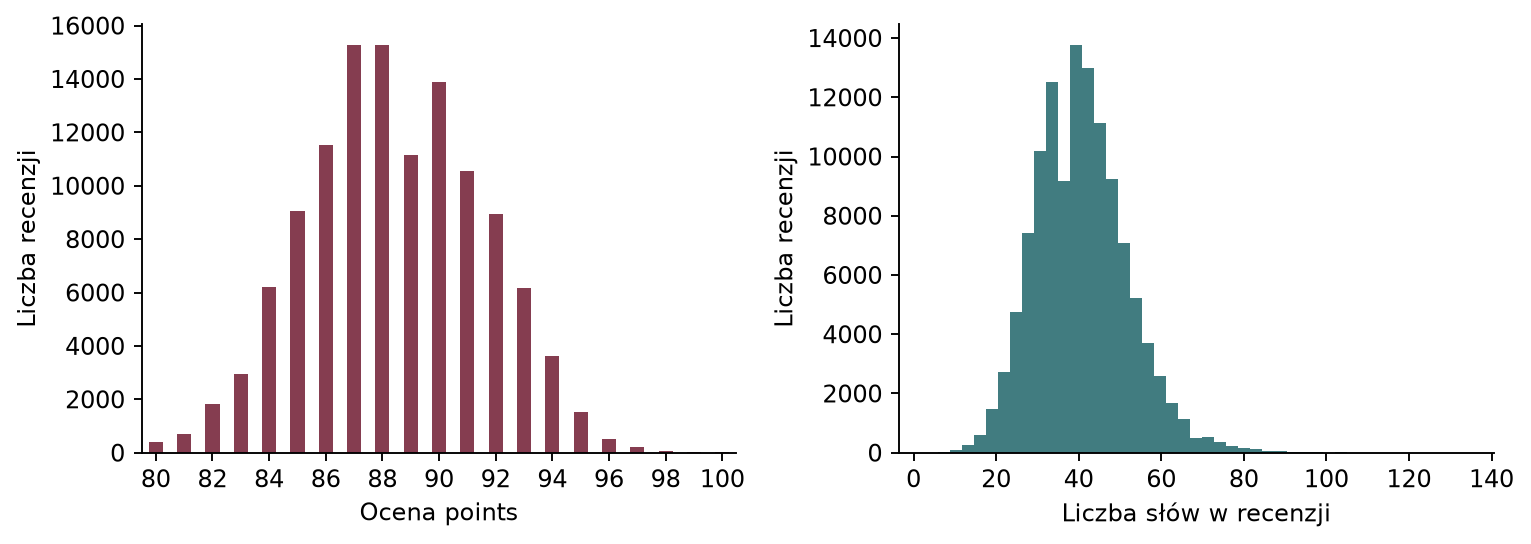

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
score_counts = reviews.points.value_counts().sort_index()
score_counts.plot.bar(ax=axes[0], color=COLORS[0], rot=0)
axes[0].set_xticks(range(0, len(score_counts), 2))
axes[0].set_xticklabels(score_counts.index[::2])
axes[0].set(xlabel="Ocena points", ylabel="Liczba recenzji")
reviews.word_count.plot.hist(ax=axes[1], bins=45, color=COLORS[1])
axes[1].set(xlabel="Liczba słów w recenzji", ylabel="Liczba recenzji")
show_plot("04_reviews_distribution")

Po czyszczeniu pozostaje 119 954 recenzji; 111 566 ma cenę. Nie ma braków tekstu ani ocen.
Mediana oceny wynosi 88, a długości opisu 40 słów. Liczba słów nie jest liczbą tokenów transformera.

## 3. Cena i długość opisu a ocena

Cena ma prawostronnie asymetryczny rozkład. Zależność ceny od oceny sprawdzamy też
wewnątrz pięciu najliczniejszych odmian. Nie jest to jednoczesna kontrola kraju, autora i producenta.

In [8]:
display(priced.price.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))
print(f"Spearman cena–ocena: {priced.price.corr(priced.points, method='spearman'):.3f}")
print(f"Pearson cena–ocena: {priced.price.corr(priced.points):.3f}")
print(f"Spearman długość–ocena: {reviews.word_count.corr(reviews.points, method='spearman'):.3f}")

price_by_variety = []
for variety in priced.variety.value_counts().head(5).index:
    group = priced.loc[priced.variety == variety]
    price_by_variety.append({
        "variety": variety, "n": len(group),
        "rho": group.price.corr(group.points, method="spearman"),
    })
show_table(pd.DataFrame(price_by_variety), "price_by_variety")
show_table(priced.groupby("points").price.agg(n="size", median_price="median", mean_price="mean"),
           "price_by_points")

before = distinct_reviews.loc[distinct_reviews.price > 0]
print(f"Spearman cena–ocena przed usunięciem powtórzonych opisów: "
      f"{before.price.corr(before.points, method='spearman'):.3f}")

Spearman cena–ocena: 0.613
Pearson cena–ocena: 0.417
Spearman długość–ocena: 0.505
Spearman cena–ocena przed usunięciem powtórzonych opisów: 0.612


count    111566.00
mean         35.62
std          42.11
min           4.00
25%          17.00
50%          25.00
75%          42.00
95%          85.00
99%         160.00
max        3300.00
Name: price, dtype: float64

,variety,n,rho
0,Pinot Noir,11834,0.630
1,Chardonnay,10237,0.688
2,Cabernet Sauvignon,8760,0.652
3,Red Blend,7805,0.547
4,Bordeaux-style Red Blend,4958,0.621


,n,median_price,mean_price
points,,,
80,395,14.0,16.372
81,677,14.0,17.145
82,1748,15.0,18.906
83,2830,15.0,18.244
84,5858,15.0,19.246
85,8470,16.0,20.017
86,10745,18.0,22.117
87,14219,20.0,24.911
88,14206,24.0,28.798


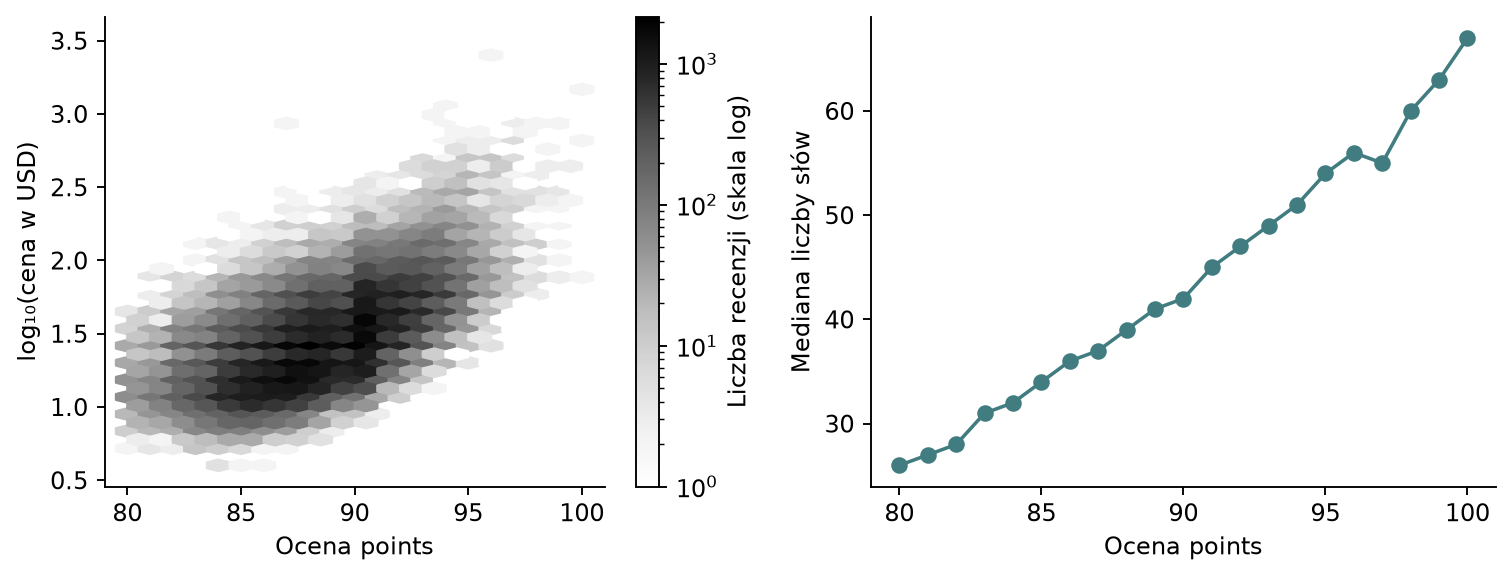

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
counts = axes[0].hexbin(
    priced.points, np.log10(priced.price), gridsize=(20, 25), mincnt=1, bins="log", cmap="Greys"
)
axes[0].set(xlabel="Ocena points", ylabel="log₁₀(cena w USD)")
fig.colorbar(counts, ax=axes[0], label="Liczba recenzji (skala log)")
reviews.groupby("points").word_count.median().plot(ax=axes[1], marker="o", color=COLORS[1])
axes[1].set(xlabel="Ocena points", ylabel="Mediana liczby słów")
show_plot("05_price_length")

Dodatni związek ceny z oceną (ρ około 0,61) nie gwarantuje wyższej jakości pojedynczej butelki.
Długość opisu też wiąże się z oceną (ρ około 0,51), dlatego przyszły model NLP warto porównać
z modelem wykorzystującym wyłącznie długość tekstu.

## 4. Słownictwo a ocena

Porównujemy `points ≥ 90` i `points ≤ 85`; środek pomijamy tylko tutaj. Liczymy obecność słowa
w recenzji, po usunięciu angielskich stop words. Zachowujemy słowa o długości co najmniej 3,
obecne łącznie w co najmniej 100 opisach obu grup. Ranking opiera się na różnicy częstości w p.p.

In [10]:
stop_words = set(ENGLISH_STOP_WORDS) | {"wine", "wines"}
groups = {"high": reviews.loc[reviews.points >= 90], "low": reviews.loc[reviews.points <= 85]}
frequencies = {}
for name, group in groups.items():
    counter = Counter()
    for description in group.description:
        words = {word for word in re.findall(r"[a-z]+", description.lower())
                 if len(word) >= 3 and word not in stop_words}
        counter.update(words)
    frequencies[name] = counter

words = pd.DataFrame(frequencies).fillna(0).astype(int)
words = words.loc[words.sum(axis=1) >= 100]
words.columns = ["high_df", "low_df"]
words["high_pct"] = 100 * words.high_df / len(groups["high"])
words["low_pct"] = 100 * words.low_df / len(groups["low"])
words["difference_pp"] = words.high_pct - words.low_pct
words.index.name = "word"
words = words.sort_values(["difference_pp", "word"], ascending=[False, True])
words.to_csv(TABLES / "word_associations.csv", encoding="utf-8-sig")
print("Liczebności grup:", {name: len(group) for name, group in groups.items()})
display(pd.concat([words.head(5), words.tail(5)]).round(3))

Liczebności grup: {'high': 45579, 'low': 21151}


,high_df,low_df,high_pct,low_pct,difference_pp
word,,,,,
black,11676,1714,25.617,8.104,17.513
rich,8990,803,19.724,3.797,15.927
tannins,12691,2854,27.844,13.493,14.351
ripe,11067,2159,24.281,10.208,14.073
drink,12899,3288,28.300,15.545,12.755
sweet,3802,3194,8.342,15.101,-6.759
light,2754,2714,6.042,12.832,-6.789
soft,3263,3074,7.159,14.534,-7.375
simple,91,2080,0.200,9.834,-9.634


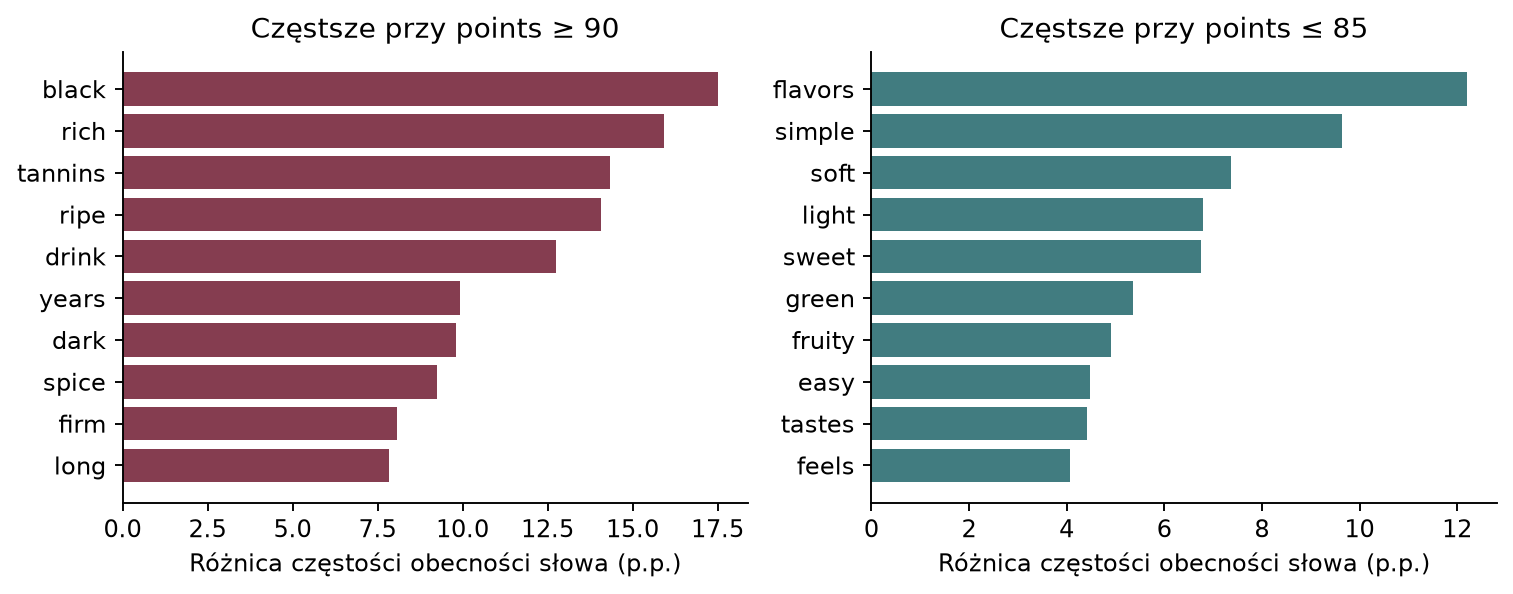

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, frame, title, color in zip(
    axes, [words.head(10), words.tail(10).iloc[::-1]],
    ["Częstsze przy points ≥ 90", "Częstsze przy points ≤ 85"], COLORS,
):
    frame = frame.iloc[::-1]
    ax.barh(frame.index, frame.difference_pp.abs(), color=color)
    ax.set(title=title, xlabel="Różnica częstości obecności słowa (p.p.)")
show_plot("06_words")

Wyżej oceniane opisy częściej zawierają m.in. rich, tannins i ripe, a niżej oceniane — simple,
soft i light. To porównanie opisowe bez kontroli długości, odmiany i autora. Nie jest testem
istotności ani listą uniwersalnych cech dobrego wina. Grupa ≤ 85 nie oznacza negatywnych opinii.

## 5. Pytania badawcze i plan weryfikacji

**Pytanie główne:** Jakie informacje o ocenianej jakości wina zawierają pomiary fizykochemiczne i opisy degustacyjne oraz jakie wzorce można rozpoznać w każdym z tych źródeł?

1. **Które cechy fizykochemiczne najsilniej wiążą się z oceną jakości i czy zależności różnią się między winami czerwonymi a białymi?**
   Hipoteza robocza: dodatnia zależność alkoholu występuje w obu typach, a znaczenie pozostałych cech jest różne.
   Metody: korelacje i rozkłady; później regresja liniowa/Ridge i random forest oraz baza medianowa. MAE/RMSE.
2. **Czy treść opisu degustacyjnego pozwala przewidywać ocenę lepiej niż sama długość recenzji?**
   Hipoteza: treść wnosi dodatkową informację. Później porównanie bazy medianowej, modelu długości,
   TF-IDF + Ridge i embeddingów transformera + regresji na tym samym podziale i z tymi samymi metrykami.
   Wejściem tekstowym jest wyłącznie `description`, bez `points`, tytułu i ceny.
3. **Czy dodatnia zależność ceny od oceny występuje także w obrębie porównywalnych grup win?**
   Hipoteza: kierunek jest dodatni również wewnątrz popularnych odmian. Spearman i mediany w grupach n ≥ 100;
   następnie uwzględnienie kraju i autora, z raportowaniem braków cen i liczebności.
4. **Czy bez użycia ocen można odkryć grupy win lub opisów, które różnią się później rozkładem ocen?**
   Hipoteza: występują interpretowalne grupy o różnych profilach i ocenach. Później K-means i klasteryzacja hierarchiczna,
   osobno dla cech chemicznych i reprezentacji tekstu. Ocena nie jest cechą ani kryterium doboru liczby grup.
   Silhouette, stabilność i interpretowalność; oceny porównujemy po ustaleniu grup.

Hipotezy powstały po obejrzeniu całej próby i są eksploracyjne. Obecna analiza nie mierzy jakości predykcji.
Przed modelowaniem ustal podział danych, grupuj rekordy tego samego wina i dopasowuj preprocessing tylko na treningu.
UCI i Wine Reviews nie są reprezentatywnymi próbami całego rynku, a surowych błędów na ich różnych skalach nie porównujemy.

Szczegółowy raport: `output/analiza_danych_i_pytania_badawcze.pdf`.
Do pełnego raportu etapu trzeba jeszcze dodać rzeczywiste dane zespołu i adres własnego repozytorium.